<a href="https://colab.research.google.com/github/kenichiy19/1CCPK-MLAM/blob/main/Sprints/2026_2/Sprint%2004/colab%20notebook/MLAM_SPRINT_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação da Produção de Energia Renovável com Modelo Linear

**Challenge Sprint 4**

**Integrantes:**
- Felipe Pereira Restivo - RM: 570712
- Gabriel Rodrigues Zappelloni - RM: 572060
- Kenichi Caio Yamamoto - RM: 569815
- Maykon de Lima Silva - RM: 574022
- Rodger Costa Rios - RM: 571438

## Introdução

Neste trabalho, utilizamos o dataset `Renewable Energy Production` (2010–2020) para classificar a produção de energia renovável em três categorias: baixa (Low), média (Medium) e alta (High). Para isso, aplicamos um modelo de classificação linear e comparamos seu desempenho em duas divisões diferentes entre dados de treino e de teste.

## Importações

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             ConfusionMatrixDisplay, classification_report)

os.makedirs("imagens", exist_ok=True)

# 1. Análise do dataset

## 1a) Carregamento do dataset

In [2]:
df = pd.read_csv("/content/Renewable_Energy_Data.csv")
print("Formato:", df.shape)
df.info()
df.head()

Formato: (1000, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Region                  1000 non-null   object 
 1   Energy_Source           1000 non-null   object 
 2   Temperature_C           1000 non-null   float64
 3   Wind_Speed_m_s          1000 non-null   float64
 4   Solar_Radiation_kWh_m2  1000 non-null   float64
 5   Rainfall_mm             1000 non-null   float64
 6   Season                  1000 non-null   object 
 7   Efficiency_Ratio        1000 non-null   float64
 8   Lagged_Production_MWh   1000 non-null   float64
 9   Combined_Weather_Index  1000 non-null   float64
 10  Energy_Class            1000 non-null   object 
dtypes: float64(7), object(4)
memory usage: 86.1+ KB


,Region,Energy_Source,Temperature_C,Wind_Speed_m_s,Solar_Radiation_kWh_m2,Rainfall_mm,Season,Efficiency_Ratio,Lagged_Production_MWh,Combined_Weather_Index,Energy_Class
0,North,Hydro,13.820937,14.362462,8.834648,3.350827,Winter,125.449109,1419.514155,1.565158,Medium
1,North,Solar,36.972782,19.110474,4.483191,48.767157,Winter,16.325089,4769.329958,0.621331,Low
2,East,Hydro,33.972875,0.364652,5.104325,40.848695,Winter,155.637061,1005.077719,0.156378,High
3,South,Solar,-2.965160,3.915560,6.265925,42.627371,Spring,675.516566,6294.250931,-5.180996,High
4,North,Wind,-3.813486,0.151257,9.263826,46.898262,Spring,626.048277,5550.263638,-3.346412,Medium


## 1b) Encoding da variável-alvo

In [3]:
print(df["Energy_Class"].value_counts())

mapa = {"Low": 0, "Medium": 1, "High": 2}
df["Energy_Class_enc"] = df["Energy_Class"].map(mapa)

df[["Energy_Class", "Energy_Class_enc"]].head()

Energy_Class
High      486
Medium    336
Low       178
Name: count, dtype: int64


,Energy_Class,Energy_Class_enc
0,Medium,1
1,Low,0
2,High,2
3,High,2
4,Medium,1


## 1c) Matriz de correlação

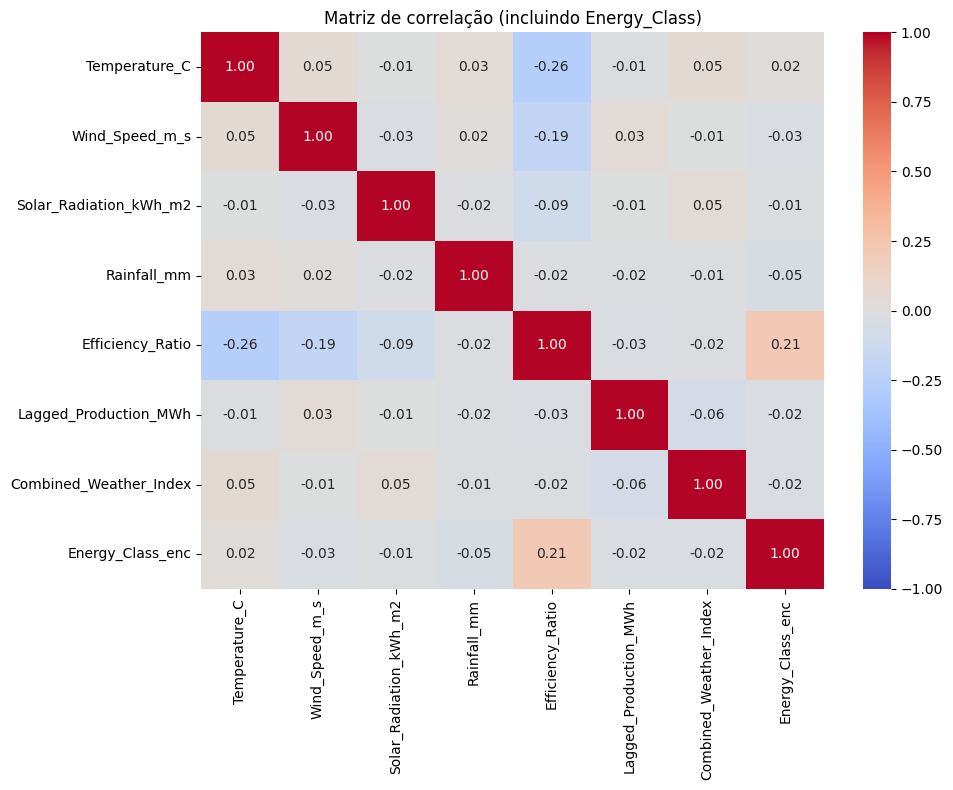

In [4]:
num = df.select_dtypes(include="number")
corr = num.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlação (incluindo Energy_Class)")
plt.tight_layout()
plt.savefig("imagens/matriz_correlacao.png", dpi=150)
plt.show()

In [5]:
corr["Energy_Class_enc"].drop("Energy_Class_enc").abs().sort_values(ascending=False)

,Energy_Class_enc
Efficiency_Ratio,0.211202
Rainfall_mm,0.045958
Wind_Speed_m_s,0.027079
Combined_Weather_Index,0.024515
Lagged_Production_MWh,0.023716
Temperature_C,0.017666
Solar_Radiation_kWh_m2,0.007859


## 1d) Seleção de features

In [6]:
features = [
    "Temperature_C", "Wind_Speed_m_s", "Solar_Radiation_kWh_m2", "Rainfall_mm",
    "Efficiency_Ratio", "Lagged_Production_MWh", "Combined_Weather_Index",
]

X = df[features]
y = df["Energy_Class_enc"]

In [7]:
def acuracia_com(feats, test_size=0.40, seed=42):
    X_tr, X_te, y_tr, y_te = train_test_split(
        df[feats], y, test_size=test_size, random_state=seed, stratify=y)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
    return accuracy_score(y_te, m.predict(X_te))

print(f"Todas as features: {acuracia_com(features):.3f}")
for f in features:
    print(f"Sem {f}: {acuracia_com([x for x in features if x != f]):.3f}")

Todas as features: 0.790
Sem Temperature_C: 0.738
Sem Wind_Speed_m_s: 0.772
Sem Solar_Radiation_kWh_m2: 0.785
Sem Rainfall_mm: 0.795
Sem Efficiency_Ratio: 0.487
Sem Lagged_Production_MWh: 0.780
Sem Combined_Weather_Index: 0.790


Pela matriz de correlação, apenas a `Efficiency_Ratio` tem alguma relação com a classe de energia (correlação de 0,21). As outras features ficaram muito próximas de zero. Também não encontramos correlações fortes entre as próprias features, o que significa que nenhuma delas repete a informação de outra.

Olhando só para esses números, faria sentido usar apenas a `Efficiency_Ratio`. Porém, a correlação mede apenas a relação linear entre duas variáveis de cada vez e não mostra como elas funcionam juntas. Para testar isso, treinamos o modelo retirando uma feature por vez. Com todas as features, a acurácia foi de 79,0%. Ao retirar a Temperature_C, ela caiu para 73,8%, mesmo essa feature tendo correlação quase nula com a classe. Já sem a `Efficiency_Ratio`, a acurácia caiu para 48,8%, um resultado tão ruim quanto chutar sempre a classe mais comum.

Por isso, decidimos usar todas as features numéricas. Como elas não são redundantes, mantê-las não atrapalha o modelo, e algumas ajudam na classificação quando combinadas com a `Efficiency_Ratio`.

Utilizamos apenas as features numéricas, pois a matriz de correlação, que é a base da análise pedida, só pode ser calculada com variáveis numéricas. As colunas de texto (`Region`, `Energy_Source` e `Season`) exigiriam uma transformação adicional e ficaram fora do escopo desta análise.

# 2. Definição e aplicação do modelo

## 2a/2b) Escolha do modelo e fronteira de decisão

Escolhemos a Regressão Logística (LogisticRegression, do scikit-learn). Apesar do nome, ela é usada para classificação: o modelo calcula a probabilidade de cada amostra pertencer a cada classe e escolhe a mais provável.

Ela é considerada um modelo linear porque sua decisão se baseia em uma soma ponderada das features: cada variável é multiplicada por um peso, aprendido durante o treinamento, e os resultados são somados. A fronteira de decisão, que é a “linha” que separa uma classe da outra, é sempre reta. Com duas features, ela é uma reta; com três, um plano; com mais features, uma superfície plana em várias dimensões, chamada hiperplano. Ou seja, o modelo não consegue criar fronteiras curvas.

Antes de treinar, padronizamos as features com o StandardScaler, que coloca todas na mesma escala. Sem isso, variáveis com valores muito grandes, como a `Lagged_Production_MWh`, poderiam ter um peso desproporcional no modelo.

## 2c/2d) Treinamento nos dois cenários

Para que a comparação seja justa, os dois cenários usam exatamente as mesmas condições: mesmas features, mesmo modelo, mesma semente aleatória (`random_state=42`) e divisão estratificada (`stratify=y`), que mantém a mesma proporção de classes no treino e no teste. A única diferença é o tamanho do conjunto de teste: 40% no Cenário 1 e 15% no Cenário 2.

In [8]:
def rodar_cenario(test_size, seed=42):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y)
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    modelo.fit(X_tr, y_tr)
    return y_te, modelo.predict(X_te)

cenarios = {
    "Cenario 1 (60/40)": 0.40,
    "Cenario 2 (85/15)": 0.15,
}

resultados = {}
for nome, ts in cenarios.items():
    resultados[nome] = rodar_cenario(ts)
    print(f"{nome}: {len(resultados[nome][0])} amostras de teste")

Cenario 1 (60/40): 400 amostras de teste
Cenario 2 (85/15): 150 amostras de teste


# 3. Avaliação da performance

## 3a) Matrizes de confusão

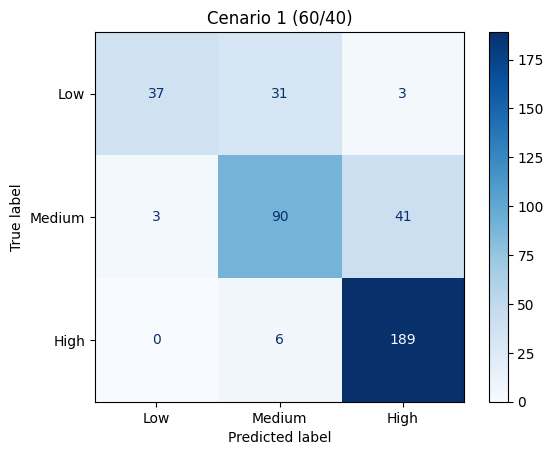

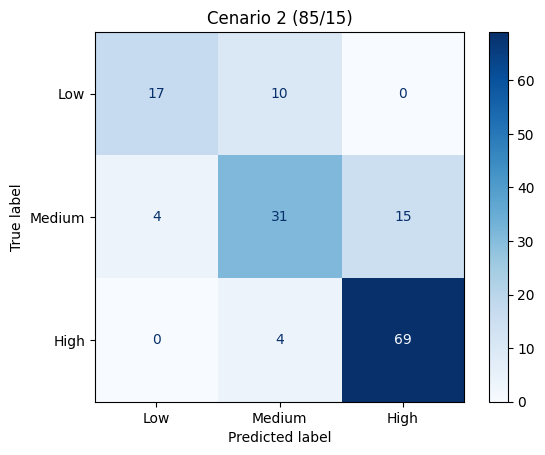

In [9]:
rotulos = ["Low", "Medium", "High"]

for i, (nome, (y_te, pred)) in enumerate(resultados.items(), start=1):
    ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=rotulos, cmap="Blues")
    plt.title(nome)
    plt.savefig(f"imagens/matriz_confusao_cenario{i}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 3b) Métricas

In [10]:
tabela = []
for nome, (y_te, pred) in resultados.items():
    tabela.append({
        "Cenário": nome,
        "Acurácia": accuracy_score(y_te, pred),
        "Precisão (macro)": precision_score(y_te, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_te, pred, average="macro", zero_division=0),
    })

metricas = pd.DataFrame(tabela).round(3)
metricas.to_csv("imagens/metricas.csv", index=False)
metricas

,Cenário,Acurácia,Precisão (macro),Recall (macro)
0,Cenario 1 (60/40),0.79,0.815,0.721
1,Cenario 2 (85/15),0.78,0.773,0.732


In [11]:
baseline = y.value_counts(normalize=True).max()
print(f"Acurácia de referência (sempre 'High'): {baseline:.3f}")

Acurácia de referência (sempre 'High'): 0.486


## 3c) Análise do desempenho

In [12]:
for nome, (y_te, pred) in resultados.items():
    print(nome)
    print(classification_report(y_te, pred, target_names=rotulos, zero_division=0))

Cenario 1 (60/40)
              precision    recall  f1-score   support

         Low       0.93      0.52      0.67        71
      Medium       0.71      0.67      0.69       134
        High       0.81      0.97      0.88       195

    accuracy                           0.79       400
   macro avg       0.81      0.72      0.75       400
weighted avg       0.80      0.79      0.78       400

Cenario 2 (85/15)
              precision    recall  f1-score   support

         Low       0.81      0.63      0.71        27
      Medium       0.69      0.62      0.65        50
        High       0.82      0.95      0.88        73

    accuracy                           0.78       150
   macro avg       0.77      0.73      0.75       150
weighted avg       0.78      0.78      0.77       150



O modelo acertou 79,0% das previsões no Cenário 1 e 78,0% no Cenário 2. Para ter uma referência, um modelo que sempre respondesse “High” (a classe mais comum) acertaria 48,6%, então o resultado é bem superior a isso. A precisão média foi de 81,5% e 77,3%, e o recall médio foi de 72,1% e 73,2%. A precisão mostra quantas das previsões de uma classe estavam certas, e o recall mostra quantas amostras de cada classe o modelo conseguiu encontrar.

O desempenho, porém, não é igual para todas as classes. O modelo reconhece muito bem a classe High (recall de 97% e 95%), mas tem dificuldade com a classe Low (52% e 63%), que é a que tem menos exemplos no dataset. Pelas matrizes de confusão, quase todos os erros acontecem entre classes vizinhas: Low é confundida com Medium, e Medium com High. Quase não há confusão entre Low e High, o que faz sentido, já que são as categorias mais distantes.

Consideramos o desempenho adequado para um modelo linear simples, mas com uma limitação importante: se o objetivo fosse identificar períodos de baixa produção, o modelo ainda deixaria passar muitos desses casos.

## 3d) Comparação entre cenários

In [13]:
linhas = []
for nome, ts in cenarios.items():
    for seed in range(30):
        y_te, pred = rodar_cenario(ts, seed)
        linhas.append({"Cenário": nome, "seed": seed, "Acurácia": accuracy_score(y_te, pred)})

var = pd.DataFrame(linhas)
resumo = var.groupby("Cenário")["Acurácia"].agg(["mean", "std", "min", "max"]).round(3)
resumo.to_csv("imagens/variacao_acuracia.csv")
resumo

,mean,std,min,max
Cenário,,,,
Cenario 1 (60/40),0.792,0.034,0.708,0.842
Cenario 2 (85/15),0.800,0.028,0.740,0.860


Os dois cenários tiveram resultados bem parecidos, com diferença de apenas um ponto percentual na acurácia (79,0% e 78,0%). O Cenário 2, que teve mais dados para treinar, foi um pouco melhor no recall, principalmente na classe Low (63% contra 52%). Já o Cenário 1 teve uma precisão média maior.

Para saber se essas diferenças eram reais ou apenas sorte da divisão, repetimos cada cenário 30 vezes, com divisões aleatórias diferentes. As médias de acurácia ficaram muito próximas (79,2% e 80,0%). Isso indica que a diferença observada depende mais de quais amostras caíram no teste do que da proporção escolhida.

## 3e) Tamanho do conjunto de teste

Um conjunto de teste maior, como no Cenário 1 (40%, ou 400 amostras), deixa a avaliação mais confiável, porque o resultado é calculado com mais exemplos e um erro isolado pesa menos. A desvantagem é que sobram menos dados para o treino (600 amostras), o que pode prejudicar o aprendizado, principalmente das classes com poucos exemplos.

Um conjunto de teste menor, como no Cenário 2 (15%, ou 150 amostras), deixa mais dados para o treino (850 amostras), mas a avaliação fica mais sensível. Neste caso, havia apenas 27 amostras da classe Low no teste, então poucos acertos ou erros já mudam bastante o resultado dessa classe.

Nas 30 repetições, a variação da acurácia foi parecida nos dois cenários (desvio padrão de 3,4 e 2,8 pontos percentuais), o que mostra que, neste dataset, o tamanho do teste teve pouco impacto. Uma alternativa para obter uma avaliação mais confiável seria a validação cruzada, técnica que divide os dados em várias partes e repete o treino e o teste alternando essas partes, usando a média dos resultados.

# Conclusão

A Regressão Logística alcançou cerca de 79% de acurácia na classificação da produção de energia, com resultados semelhantes nos dois cenários de divisão dos dados. A Efficiency_Ratio foi a feature mais importante, mas as demais também contribuíram quando usadas em conjunto. A principal limitação do modelo foi a identificação da classe Low, que tem menos exemplos e fica próxima da classe Medium. Para melhorar esse resultado, poderiam ser testados modelos não lineares ou técnicas para equilibrar as classes no treinamento.